# Tarea 1.1 · Benchmark comparativo: Pandas vs Polars vs PySpark

**Curso:** Herramientas de Big Data · Saber 2: Procesamiento distribuido
**Proyecto:** Emergencias de la Línea 123 de Bogotá (julio, agosto y septiembre de 2026)
**Actividad:** Actividad 1 · Fase 1 · Investigación

**Objetivos**
- Medir con `measure_performance()` el tiempo y la memoria (`psutil.virtual_memory()`) de Pandas, Polars y PySpark sobre los mismos 3 archivos mensuales.
- Comparar cinco operaciones: carga y combinación de los 3 CSV, filtrado de USAQUÉN y CHAPINERO, agregación por tipo de incidente, join con la tabla de códigos y exportación a Parquet.
- Documentar la complejidad del código (líneas por operación) y comprobar que las tres herramientas llegan al mismo resultado.

**Prerrequisitos**
- Los 3 CSV en `MyDrive/BigData_U2/datos/`.
- Notebooks del curso 02 (SparkSession), 03 (sintaxis) y 04 (formatos y `measure_operation`).

**Tiempo estimado de ejecución:** ~6 minutos (Colab gratuito, solo CPU)

**Dataset:** «Llamadas de urgencias y emergencias que ingresan a través de la línea 123», Secretaría Distrital de
Salud, portal Datos Abiertos Bogotá (CC BY 4.0). Tres CSV mensuales (27 434 registros, separador `;`).

## 1. Configuración del entorno

Igual que en los notebooks del curso: se monta Drive, se importan las librerías y se definen las funciones de
monitoreo. `measure_performance()` es la adaptación de `measure_operation()` (notebook 04 del curso) que pide la guía:
mide el tiempo con `time.time()` y la memoria con `psutil.virtual_memory()`; además registra el **pico** de memoria
con un muestreo cada 50 ms, porque Spark usa la memoria en otro proceso (la JVM) y solo se ve en el % del sistema.

In [ ]:
# 1.1 Conexión con Google Drive (los datos y los resultados viven en MyDrive/BigData_U2)
import os
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# 1.2 Librerías
import time, json, inspect, threading, platform, gc, shutil
import numpy as np
import pandas as pd
import polars as pl
import psutil
import matplotlib.pyplot as plt
import pyspark
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)

os.environ['TZ'] = 'America/Bogota'   # hora local en los logs
time.tzset()

# 1.3 Rutas de trabajo (una sola carpeta del proyecto en Drive)
BASE = '/content/drive/MyDrive/BigData_U2'
DATOS = f'{BASE}/datos'
RESULTADOS = f'{BASE}/resultados'
MEDICIONES = f'{RESULTADOS}/mediciones'
for ruta in (RESULTADOS, MEDICIONES, f'{RESULTADOS}/logs', f'{RESULTADOS}/parquet'):
    os.makedirs(ruta, exist_ok=True)

ARCHIVOS = ['llamadas123_julio_2026.csv', 'llamadaslinea123agosto2026.csv', 'llamadaslinea123Septiembre.csv']
RUTAS = [f'{DATOS}/{a}' for a in ARCHIVOS]
COLUMNAS = ['NUMERO_INCIDENTE', 'FECHA_INICIO_DESPLAZAMIENTO_MOVIL', 'CODIGO_LOCALIDAD', 'LOCALIDAD', 'EDAD',
            'UNIDAD', 'GENERO', 'TIPO_INCIDENTE', 'PRIORIDAD_FINAL', 'RECEPCION']
faltan = [a for a in ARCHIVOS if not os.path.exists(f'{DATOS}/{a}')]
assert not faltan, f'Sube a {DATOS} los archivos: {faltan}'

print('✓ Drive montado y librerías importadas')
print(f'   Python {platform.python_version()} · pandas {pd.__version__} · polars {pl.__version__} · '
      f'PySpark {pyspark.__version__}')

✓ Drive montado y librerías importadas
   Python 3.13.18 · pandas 2.2.3 · polars 1.35.2 · PySpark 4.0.5


In [ ]:
# 1.4 Funciones de monitoreo (notebook 02 del curso: get_memory_info / print_memory_status)
def get_memory_info():
    """Obtiene información sobre el uso de memoria del sistema."""
    memory = psutil.virtual_memory()
    return {'total_gb': round(memory.total / 1024**3, 2), 'disponible_gb': round(memory.available / 1024**3, 2),
            'usado_gb': round(memory.used / 1024**3, 2), 'porcentaje': memory.percent}


def print_memory_status(titulo='Estado de memoria'):
    mem = get_memory_info()
    print(f"\n📊 {titulo}: {mem['usado_gb']} de {mem['total_gb']} GB usados ({mem['porcentaje']:.1f} %), "
          f"{mem['disponible_gb']} GB disponibles")


class MonitorMemoria:
    """Muestrea psutil.virtual_memory().percent cada 50 ms para capturar el PICO de memoria durante una operación."""

    def __init__(self, intervalo=0.05):
        self.intervalo, self.pico, self._activo = intervalo, 0.0, False

    def _muestrear(self):
        while self._activo:
            self.pico = max(self.pico, psutil.virtual_memory().percent)
            time.sleep(self.intervalo)

    def __enter__(self):
        self.pico, self._activo = psutil.virtual_memory().percent, True
        self._hilo = threading.Thread(target=self._muestrear, daemon=True)
        self._hilo.start()
        return self

    def __exit__(self, *exc):
        self._activo = False
        self._hilo.join()


def measure_performance(func, *args, **kwargs):
    """Mide tiempo y memoria de una operación (adaptación de measure_operation, notebook 04 del curso).

    - Tiempo: time.time() antes y después.
    - Memoria: psutil.virtual_memory() (porcentaje del sistema antes y pico durante la operación) y el cambio de
      RSS del proceso Python. El % del sistema incluye la JVM de Spark, que corre en otro proceso.
    """
    proceso = psutil.Process()
    rss_antes = proceso.memory_info().rss / 1024**2
    mem_antes = psutil.virtual_memory().percent
    with MonitorMemoria() as monitor:
        inicio = time.time()
        resultado = func(*args, **kwargs)
        fin = time.time()
    return {'result': resultado, 'time_seconds': fin - inicio, 'mem_pct_antes': mem_antes,
            'mem_pct_pico': monitor.pico, 'memory_delta_mb': proceso.memory_info().rss / 1024**2 - rss_antes}


print('✓ Funciones de medición configuradas')
print_memory_status('Memoria inicial')

✓ Funciones de medición configuradas

📊 Memoria inicial: 0.86 de 12.67 GB usados (9.3 %), 11.49 GB disponibles


## 2. Datos de entrada

Tres meses consecutivos de llamadas a la Línea 123. Todos los campos se leen como texto, para que las tres
herramientas partan exactamente de lo mismo.

In [ ]:
resumen_archivos = pd.DataFrame([
    {'archivo': a, 'tamaño_MB': round(os.path.getsize(r) / 1024**2, 2),
     'registros': len(pd.read_csv(r, sep=';', dtype=str, encoding='utf-8-sig', usecols=['NUMERO_INCIDENTE']))}
    for a, r in zip(ARCHIVOS, RUTAS)])
print(f"Total: {resumen_archivos['registros'].sum():,} registros en {resumen_archivos['tamaño_MB'].sum():.2f} MB")
resumen_archivos

Total: 27,434 registros en 2.95 MB


,archivo,tamaño_MB,registros
0,llamadas123_julio_2026.csv,0.960,8965
1,llamadaslinea123agosto2026.csv,0.990,9204
2,llamadaslinea123Septiembre.csv,1.000,9265


## 3. SparkSession optimizada para Colab

Se usa el helper `create_optimized_spark_session()` del notebook 02 del curso: todos los núcleos (`local[*]`), 70 % de
la memoria disponible para el driver, ejecución adaptativa (AQE), serializador Kryo y Arrow. El tiempo de arranque de
la JVM se mide aparte, porque es un costo fijo de PySpark que Pandas y Polars no tienen.

In [ ]:
# Helper del notebook 02 del curso (create_optimized_spark_session), con la zona horaria de Bogotá
def create_optimized_spark_session(app_name='Emergencias123', memory_fraction=0.7):
    """Crea una SparkSession optimizada para Google Colab."""
    num_cores = os.cpu_count()
    driver_memory = f"{int(get_memory_info()['disponible_gb'] * memory_fraction)}g"
    return (SparkSession.builder
            .appName(app_name)
            .master(f'local[{num_cores}]')
            .config('spark.driver.memory', driver_memory)
            .config('spark.sql.adaptive.enabled', 'true')
            .config('spark.sql.adaptive.coalescePartitions.enabled', 'true')
            .config('spark.serializer', 'org.apache.spark.serializer.KryoSerializer')
            .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
            .config('spark.sql.session.timeZone', 'America/Bogota')
            .config('spark.ui.showConsoleProgress', 'false')
            .getOrCreate())


m = measure_performance(create_optimized_spark_session)
spark = m['result']
TIEMPO_INICIO_SPARK = m['time_seconds']
print(f"✅ SparkSession creada en {TIEMPO_INICIO_SPARK:.2f} s")
print(f"   - Master: {spark.sparkContext.master}")
print(f"   - Paralelismo por defecto: {spark.sparkContext.defaultParallelism}")
print(f"   - Driver memory: {spark.conf.get('spark.driver.memory')}")
print(f"   - AQE: {spark.conf.get('spark.sql.adaptive.enabled')} · Serializador: Kryo · Arrow: activado")
print('\n💡 En Colab, Spark corre en modo local: driver y ejecutores comparten una JVM en un solo nodo (no es un clúster).')

✅ SparkSession creada en 10.14 s
   - Master: local[2]
   - Paralelismo por defecto: 2


   - Driver memory: 8g
   - AQE: true · Serializador: Kryo · Arrow: activado

💡 En Colab, Spark corre en modo local: driver y ejecutores comparten una JVM en un solo nodo (no es un clúster).


## 4. Tabla de códigos de tipo de incidente

La operación de join necesita una tabla de códigos. Como no hay una tabla oficial publicada, se **deriva de los datos**
y se rotula como **no oficial**. Se guarda en Drive para reutilizarla en el PoC.

In [ ]:
# Normalización común a las tres herramientas: mayúsculas, sin tildes y con espacios simples.
# Necesaria porque los datos traen «USAQUÉN» con tilde y un tipo con doble espacio («AMESUI  - ...»).
CON_TILDE, SIN_TILDE = 'ÁÉÍÓÚÜÑ', 'AEIOUUN'
TABLA_TILDES = str.maketrans(CON_TILDE, SIN_TILDE)
LOCALIDADES = ['USAQUEN', 'CHAPINERO']

# Tabla de códigos de tipo de incidente: no existe una tabla oficial publicada, así que se DERIVA de los datos.
# Código = texto antes de « - » (normalizado); si el tipo no trae código, el texto completo hace de código.
tipos = pd.concat([pd.read_csv(r, sep=';', dtype=str, encoding='utf-8-sig', usecols=['TIPO_INCIDENTE'])
                   for r in RUTAS])['TIPO_INCIDENTE'].dropna().unique()
filas = []
for texto in sorted(tipos):
    norm = ' '.join(texto.upper().translate(TABLA_TILDES).split())
    codigo, _, descripcion = norm.partition(' - ')
    filas.append({'codigo_tipo': codigo.strip(), 'descripcion_tipo': (descripcion or codigo).strip(),
                  'codigo_explicito': bool(descripcion), 'fuente': 'derivado de los datos, no oficial'})
catalogo = pd.DataFrame(filas).drop_duplicates('codigo_tipo').reset_index(drop=True)
assert catalogo['codigo_tipo'].is_unique
RUTA_CATALOGO = f'{RESULTADOS}/catalogo_tipos_derivado.csv'
catalogo.to_csv(RUTA_CATALOGO, index=False)
print(f'Catálogo derivado (NO oficial): {len(catalogo)} códigos, '
      f"{int(catalogo['codigo_explicito'].sum())} con código explícito → {RUTA_CATALOGO}")
catalogo

Catálogo derivado (NO oficial): 23 códigos, 19 con código explícito → /content/drive/MyDrive/BigData_U2/resultados/catalogo_tipos_derivado.csv


,codigo_tipo,descripcion_tipo,codigo_explicito,fuente
0,ACCAVI,ACCIDENTE DE AVIACION,True,"derivado de los datos, no oficial"
1,ACOMPANAMIENTO A EVENTO,ACOMPANAMIENTO A EVENTO,False,"derivado de los datos, no oficial"
2,ACV,ACCIDENTE CEREBRO VASCULAR,True,"derivado de los datos, no oficial"
3,AMESUI,AMENAZA DE SUICIDIO,True,"derivado de los datos, no oficial"
4,APOYO CRUE,APOYO CRUE,False,"derivado de los datos, no oficial"
5,CAIALT,CAIDA DE ALTURA,True,"derivado de los datos, no oficial"
6,CONVULSION,CONVULSION,True,"derivado de los datos, no oficial"
7,DOLTOR,DOLOR TORACICO,True,"derivado de los datos, no oficial"
8,ELECTROCUC,ELECTROCUCION / RESCATE,True,"derivado de los datos, no oficial"
9,ENFERMO,ENFERMO,False,"derivado de los datos, no oficial"


## 5. Las cinco operaciones en cada herramienta

La misma lógica en las tres. En el filtrado se crean dos columnas: `localidad_norm` (sin tildes, para encontrar
«USAQUÉN») y `codigo_tipo` (el código antes de « - »), que usan la agregación y el join.

**Evaluación perezosa (notebook 02 del curso).** PySpark solo define un plan hasta que llega una *acción*. Para medir
cada operación por separado, después de cada transformación se ejecuta `cache()` + `count()` (función
`materializar`); sin eso, el filtrado «tardaría» 0 s y todo el costo aparecería en la exportación.

In [ ]:
# ---------------- PANDAS
def pandas_carga(rutas):
    return pd.concat([pd.read_csv(r, sep=';', dtype=str, encoding='utf-8-sig', keep_default_na=False, na_values=[''])
                      for r in rutas], ignore_index=True)


def pandas_filtrado(df):
    norm = lambda s: s.str.upper().str.translate(TABLA_TILDES).str.replace(r'\s+', ' ', regex=True).str.strip()
    df = df.assign(localidad_norm=norm(df['LOCALIDAD']),
                   codigo_tipo=norm(df['TIPO_INCIDENTE']).str.split(' - ', n=1).str[0].str.strip())
    return df[df['localidad_norm'].isin(LOCALIDADES)]


def pandas_agregacion(df):
    conteo = df.groupby('codigo_tipo').size().reset_index(name='conteo')
    return conteo.sort_values(['conteo', 'codigo_tipo'], ascending=[False, True])


def pandas_join(df, catalogo):
    return df.merge(catalogo, on='codigo_tipo', how='left', validate='m:1')


def pandas_exportacion(df, ruta):
    df.to_parquet(ruta, index=False)


# ---------------- POLARS
def polars_carga(rutas):
    return pl.concat([pl.read_csv(r, separator=';', infer_schema=False) for r in rutas])


def polars_filtrado(df):
    norm = lambda c: (pl.col(c).str.to_uppercase().str.replace_many(list(CON_TILDE), list(SIN_TILDE))
                      .str.replace_all(r'\s+', ' ').str.strip_chars())
    df = df.with_columns(norm('LOCALIDAD').alias('localidad_norm'),
                         norm('TIPO_INCIDENTE').str.split(' - ').list.first().str.strip_chars().alias('codigo_tipo'))
    return df.filter(pl.col('localidad_norm').is_in(LOCALIDADES))


def polars_agregacion(df):
    conteo = df.group_by('codigo_tipo').agg(pl.len().alias('conteo'))
    return conteo.sort(['conteo', 'codigo_tipo'], descending=[True, False])


def polars_join(df, catalogo):
    return df.join(catalogo, on='codigo_tipo', how='left')


def polars_exportacion(df, ruta):
    df.write_parquet(ruta)


# ---------------- PYSPARK
def spark_carga(rutas):
    return spark.read.csv(rutas, schema=StructType([StructField(c, StringType(), True) for c in COLUMNAS]),
                          sep=';', header=True, encoding='UTF-8')


def spark_filtrado(df):
    norm = lambda c: F.trim(F.regexp_replace(F.translate(F.upper(F.col(c)), CON_TILDE, SIN_TILDE), r'\s+', ' '))
    df = (df.withColumn('localidad_norm', norm('LOCALIDAD'))
            .withColumn('codigo_tipo', F.trim(F.split(norm('TIPO_INCIDENTE'), ' - ').getItem(0))))
    return df.filter(F.col('localidad_norm').isin(LOCALIDADES))


def spark_agregacion(df):
    conteo = df.groupBy('codigo_tipo').agg(F.count('*').alias('conteo'))
    return conteo.orderBy(F.desc('conteo'), F.asc('codigo_tipo'))


def spark_join(df, catalogo):
    return df.join(F.broadcast(catalogo), on='codigo_tipo', how='left')


def spark_exportacion(df, ruta):
    df.write.mode('overwrite').parquet(ruta)


def materializar(df):
    """Acción que obliga a Spark a ejecutar el plan (cache + count) para poder medir la operación."""
    df = df.cache()
    df.count()
    return df


# Tabla de códigos en el formato de cada herramienta (se prepara antes de medir)
cat_pd = catalogo[['codigo_tipo', 'descripcion_tipo']]
cat_pl = pl.from_pandas(cat_pd)
cat_sp = spark.createDataFrame(cat_pd)
print('✓ Operaciones definidas para Pandas, Polars y PySpark')

✓ Operaciones definidas para Pandas, Polars y PySpark


## 6. Ejecución del benchmark con `measure_performance()`

- **1 ronda de calentamiento** (se descarta: carga librerías y calienta la JVM) y **3 rondas medidas**.
- El **orden de las herramientas rota** en cada ronda, para que ninguna se beneficie siempre de ir primero o último.
- Entre herramientas se liberan los DataFrames (`gc.collect()`, `clearCache()`), para no sumar memoria ajena.
- La exportación escribe en el disco local del VM (`/content`), para que la latencia de Drive no distorsione la medición.

In [ ]:
SALIDA = '/content/benchmark_parquet'
os.makedirs(SALIDA, exist_ok=True)
OPERACIONES = {
    'pandas': {'carga': pandas_carga, 'filtrado': pandas_filtrado, 'agregacion': pandas_agregacion,
               'join': lambda d: pandas_join(d, cat_pd), 'exportacion': pandas_exportacion},
    'polars': {'carga': polars_carga, 'filtrado': polars_filtrado, 'agregacion': polars_agregacion,
               'join': lambda d: polars_join(d, cat_pl), 'exportacion': polars_exportacion},
    'spark': {'carga': lambda r: materializar(spark_carga(r)), 'filtrado': lambda d: materializar(spark_filtrado(d)),
              'agregacion': lambda d: materializar(spark_agregacion(d)),
              'join': lambda d: materializar(spark_join(d, cat_sp)), 'exportacion': spark_exportacion},
}
REPETICIONES = 3
mediciones, resultados = [], {}


def correr(herramienta, ronda):
    f = OPERACIONES[herramienta]

    def medir(operacion, funcion, *args):
        m = measure_performance(funcion, *args)
        mediciones.append({'herramienta': herramienta, 'ronda': ronda, 'operacion': operacion,
                           'segundos': m['time_seconds'], 'mem_pct_antes': m['mem_pct_antes'],
                           'mem_pct_pico': m['mem_pct_pico'], 'memoria_delta_mb': m['memory_delta_mb']})
        return m['result']

    df = medir('carga', f['carga'], RUTAS)
    filtrado = medir('filtrado', f['filtrado'], df)
    conteo = medir('agregacion', f['agregacion'], filtrado)
    unido = medir('join', f['join'], filtrado)
    medir('exportacion', f['exportacion'], unido, f'{SALIDA}/{herramienta}.parquet')
    return conteo, unido


HERRAMIENTAS = ['pandas', 'polars', 'spark']
for ronda in range(REPETICIONES + 1):
    orden = HERRAMIENTAS[ronda % 3:] + HERRAMIENTAS[:ronda % 3]
    etiqueta = 'calentamiento' if ronda == 0 else f'ronda {ronda}'
    for h in orden:
        conteo, unido = correr(h, ronda)
        if ronda == REPETICIONES:   # el resultado de la última ronda se usa para comprobar la equivalencia
            resultados[h] = (conteo, unido)
        del conteo, unido
        gc.collect()
        if ronda < REPETICIONES:
            spark.catalog.clearCache()
    print(f'✓ {etiqueta}: ' + ' → '.join(orden))

bench = pd.DataFrame(mediciones)
medidas = bench[bench['ronda'] > 0]
print(f'\n{len(medidas)} mediciones válidas ({REPETICIONES} rondas × 3 herramientas × 5 operaciones)')

✓ calentamiento: pandas → polars → spark


✓ ronda 1: polars → spark → pandas


✓ ronda 2: spark → pandas → polars


✓ ronda 3: pandas → polars → spark

45 mediciones válidas (3 rondas × 3 herramientas × 5 operaciones)


## 7. Resultados

### 7.1 Tiempo por operación (media de las 3 rondas, en segundos)

In [ ]:
por_operacion = medidas.pivot_table(index='operacion', columns='herramienta', values='segundos', aggfunc='mean')
por_operacion = por_operacion.loc[['carga', 'filtrado', 'agregacion', 'join', 'exportacion'], HERRAMIENTAS]
por_operacion.loc['TOTAL'] = por_operacion.sum()
por_operacion

herramienta,pandas,polars,spark
operacion,,,
carga,0.133,0.052,1.017
filtrado,0.327,0.067,0.606
agregacion,0.004,0.002,1.291
join,0.006,0.001,0.583
exportacion,0.015,0.006,0.494
TOTAL,0.485,0.128,3.992


### 7.2 Tiempo total y memoria por herramienta

In [ ]:
por_ronda = medidas.groupby(['herramienta', 'ronda']).agg(
    tiempo_total_s=('segundos', 'sum'), mem_pct_pico=('mem_pct_pico', 'max'), mem_pct_inicio=('mem_pct_antes', 'first'))
por_ronda['mem_incremento_pp'] = por_ronda['mem_pct_pico'] - por_ronda['mem_pct_inicio']
totales = por_ronda.groupby('herramienta').agg(
    tiempo_total_s=('tiempo_total_s', 'mean'), tiempo_desv_s=('tiempo_total_s', 'std'),
    mem_pct_pico=('mem_pct_pico', 'mean'), mem_incremento_pp=('mem_incremento_pp', 'mean')).loc[HERRAMIENTAS]
totales['veces_vs_mas_rapida'] = totales['tiempo_total_s'] / totales['tiempo_total_s'].min()
print(f'Arranque de la SparkSession (costo fijo, no incluido en los totales): {TIEMPO_INICIO_SPARK:.2f} s')
totales

Arranque de la SparkSession (costo fijo, no incluido en los totales): 10.14 s


,tiempo_total_s,tiempo_desv_s,mem_pct_pico,mem_incremento_pp,veces_vs_mas_rapida
herramienta,,,,,
pandas,0.485,0.170,22.133,0.033,3.777
polars,0.128,0.081,22.067,0.033,1.000
spark,3.992,0.905,22.133,0.100,31.107


### 7.3 Visualización

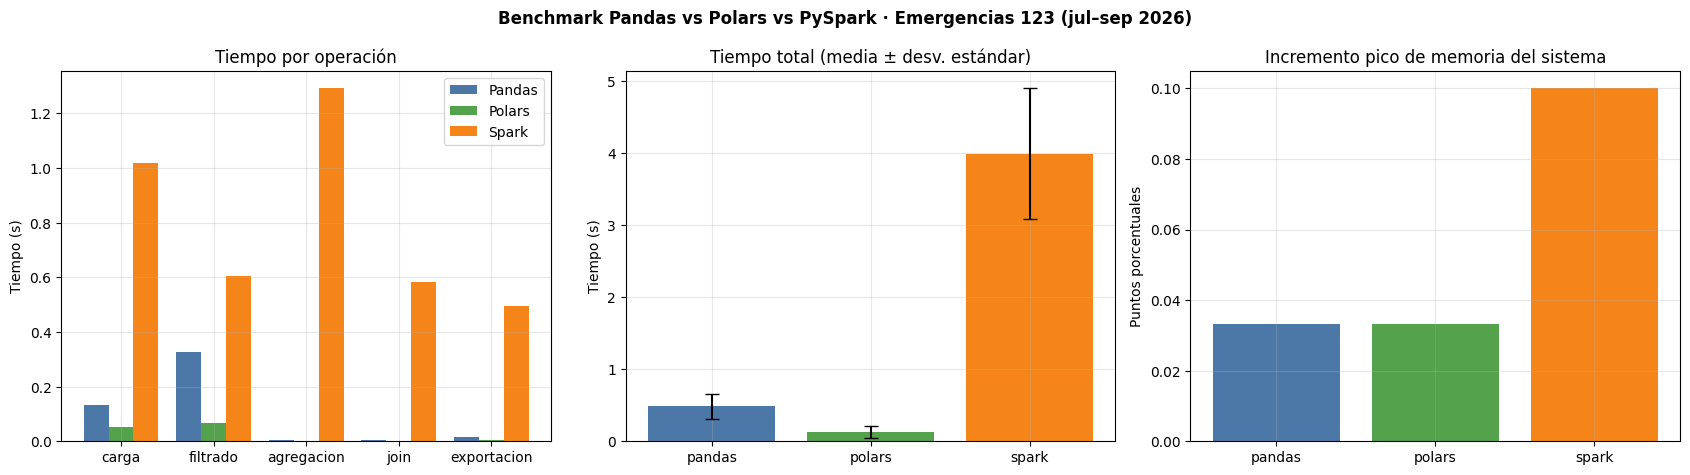

In [ ]:
colores = {'pandas': '#4C78A8', 'polars': '#54A24B', 'spark': '#F58518'}
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.8))
x = np.arange(5)
for i, h in enumerate(HERRAMIENTAS):
    ax1.bar(x + (i - 1) * 0.27, por_operacion[h].iloc[:5], 0.27, label=h.capitalize(), color=colores[h])
ax1.set_xticks(x)
ax1.set_xticklabels(por_operacion.index[:5])
ax1.set_ylabel('Tiempo (s)')
ax1.set_title('Tiempo por operación')
ax1.legend()
ax2.bar(HERRAMIENTAS, totales['tiempo_total_s'], yerr=totales['tiempo_desv_s'], capsize=5,
        color=[colores[h] for h in HERRAMIENTAS])
ax2.set_ylabel('Tiempo (s)')
ax2.set_title('Tiempo total (media ± desv. estándar)')
ax3.bar(HERRAMIENTAS, totales['mem_incremento_pp'], color=[colores[h] for h in HERRAMIENTAS])
ax3.set_ylabel('Puntos porcentuales')
ax3.set_title('Incremento pico de memoria del sistema')
for ax in (ax1, ax2, ax3):
    ax.grid(True, alpha=0.3)
plt.suptitle('Benchmark Pandas vs Polars vs PySpark · Emergencias 123 (jul–sep 2026)', fontweight='bold')
plt.tight_layout()
plt.show()

## 8. ¿Las tres herramientas producen el mismo resultado?

Un benchmark solo es válido si las herramientas hacen lo mismo. Se compara el conteo por tipo de incidente, el
número de filas después del join y las filas sin descripción (deben ser 0).

In [ ]:
def a_pandas(obj):
    if isinstance(obj, pd.DataFrame):
        return obj
    if isinstance(obj, pl.DataFrame):
        return obj.to_pandas()
    return obj.toPandas()


equivalencia = {}
for h, (conteo, unido) in resultados.items():
    c, u = a_pandas(conteo), a_pandas(unido)
    equivalencia[h] = {'filas_filtradas': int(len(u)),
                       'conteo_por_tipo': {k: int(v) for k, v in zip(c['codigo_tipo'], c['conteo'])},
                       'sin_descripcion': int(u['descripcion_tipo'].isna().sum())}
iguales = all(equivalencia[h]['conteo_por_tipo'] == equivalencia['pandas']['conteo_por_tipo'] and
              equivalencia[h]['filas_filtradas'] == equivalencia['pandas']['filas_filtradas'] for h in HERRAMIENTAS)
display(pd.DataFrame({h: {'filas USAQUÉN + CHAPINERO': v['filas_filtradas'], 'tipos distintos': len(v['conteo_por_tipo']),
                          'filas sin descripción': v['sin_descripcion']} for h, v in equivalencia.items()}))
print('✅ Las tres herramientas producen el mismo resultado' if iguales else '❌ Los resultados difieren')
print('\nTipos de incidente más frecuentes en USAQUÉN y CHAPINERO (PySpark):')
display(a_pandas(resultados['spark'][0]).head(10))
spark.catalog.clearCache()

,pandas,polars,spark
filas USAQUÉN + CHAPINERO,1762,1762,1762
tipos distintos,21,21,21
filas sin descripción,0,0,0


✅ Las tres herramientas producen el mismo resultado

Tipos de incidente más frecuentes en USAQUÉN y CHAPINERO (PySpark):


,codigo_tipo,conteo
0,HERIDO,387
1,TRASTMENT,201
2,INCONSCIEN,175
3,CONVULSION,165
4,INTSUI,159
5,ENFERMO,152
6,EVERES,138
7,DOLTOR,63
8,CAIALT,62
9,ACV,51


## 9. Complejidad del código: líneas por operación

Se cuentan las líneas de código de cada función (sin la línea `def`, sin líneas vacías ni comentarios). Es un
indicador aproximado de facilidad de uso, que alimenta la matriz de decisión (tarea 1.2).

In [ ]:
def contar_lineas(funcion):
    lineas = inspect.getsource(funcion).splitlines()[1:]
    return sum(1 for l in lineas if l.strip() and not l.strip().startswith('#'))


FUNCIONES = {'pandas': [pandas_carga, pandas_filtrado, pandas_agregacion, pandas_join, pandas_exportacion],
             'polars': [polars_carga, polars_filtrado, polars_agregacion, polars_join, polars_exportacion],
             'spark': [spark_carga, spark_filtrado, spark_agregacion, spark_join, spark_exportacion]}
loc = pd.DataFrame({h: [contar_lineas(f) for f in fs] for h, fs in FUNCIONES.items()},
                   index=['carga', 'filtrado', 'agregacion', 'join', 'exportacion'])
loc.loc['TOTAL'] = loc.sum()
print('Nota: en PySpark, materializar() solo sirve para poder medir y no se cuenta.')
loc

Nota: en PySpark, materializar() solo sirve para poder medir y no se cuenta.


,pandas,polars,spark
carga,2,1,2
filtrado,4,5,4
agregacion,2,2,2
join,1,1,1
exportacion,1,1,1
TOTAL,10,10,10


## 10. Guardar las mediciones en Drive

Son la fuente de la matriz de decisión (tarea 1.2) y de los informes.

In [ ]:
bench.to_csv(f'{MEDICIONES}/benchmark.csv', index=False)
loc.to_csv(f'{MEDICIONES}/loc_benchmark.csv')
with open(f'{MEDICIONES}/equivalencia_benchmark.json', 'w', encoding='utf-8') as f:
    json.dump({'iguales': iguales, **equivalencia}, f, indent=2, ensure_ascii=False)
entorno = {'python': platform.python_version(), 'pandas': pd.__version__, 'polars': pl.__version__,
           'pyspark': pyspark.__version__, 'vcpu': os.cpu_count(), 'ram_gb': get_memory_info()['total_gb'],
           'spark_driver_memory': spark.conf.get('spark.driver.memory'), 'inicio_spark_s': TIEMPO_INICIO_SPARK,
           'repeticiones': REPETICIONES, 'registros': int(resumen_archivos['registros'].sum()),
           'fecha': time.strftime('%Y-%m-%d %H:%M')}
with open(f'{MEDICIONES}/entorno_colab.json', 'w', encoding='utf-8') as f:
    json.dump(entorno, f, indent=2)
print('✓ Guardado en', MEDICIONES, '→', sorted(os.listdir(MEDICIONES)))

✓ Guardado en /content/drive/MyDrive/BigData_U2/resultados/mediciones → ['benchmark.csv', 'entorno_colab.json', 'equivalencia_benchmark.json', 'escalabilidad.csv', 'loc_benchmark.csv', 'matriz_decision.json', 'poc_metricas.csv', 'poc_validacion.json', 'proyeccion.csv']


## 11. Hallazgos

In [ ]:
rapida = totales['tiempo_total_s'].idxmin()
lenta = totales['tiempo_total_s'].idxmax()
print(f"• Con {resumen_archivos['registros'].sum():,} registros (~{resumen_archivos['tamaño_MB'].sum():.0f} MB), la más "
      f"rápida fue {rapida.capitalize()} ({totales.loc[rapida, 'tiempo_total_s']:.2f} s) y la más lenta "
      f"{lenta.capitalize()} ({totales.loc[lenta, 'tiempo_total_s']:.2f} s, "
      f"{totales.loc[lenta, 'veces_vs_mas_rapida']:.1f} veces más).")
print(f"• PySpark además paga {TIEMPO_INICIO_SPARK:.1f} s de arranque de la JVM, un costo fijo que con pocos datos pesa mucho.")
op_lenta = por_operacion.drop('TOTAL')['spark'].idxmax()
print(f"• La operación más costosa en PySpark fue «{op_lenta}» ({por_operacion.loc[op_lenta, 'spark']:.2f} s).")
print('• Líneas de código totales: ' + ', '.join(f"{h.capitalize()} {loc.loc['TOTAL', h]}" for h in HERRAMIENTAS) + '.')
print('• Los resultados de las tres herramientas son ' + ('idénticos.' if iguales else 'DISTINTOS: revisar.'))

• Con 27,434 registros (~3 MB), la más rápida fue Polars (0.13 s) y la más lenta Spark (3.99 s, 31.1 veces más).
• PySpark además paga 10.1 s de arranque de la JVM, un costo fijo que con pocos datos pesa mucho.
• La operación más costosa en PySpark fue «agregacion» (1.29 s).
• Líneas de código totales: Pandas 10, Polars 10, Spark 10.
• Los resultados de las tres herramientas son idénticos.


**Interpretación.** Con un volumen pequeño dominan los costos fijos de PySpark (JVM, planificación, serialización
entre Python y Java), así que Pandas y Polars ganan en tiempo, y así se reporta. La razón para usar PySpark es que
escala horizontalmente a un clúster cuando los datos dejan de caber en una sola máquina (ver la tarea 2.4).

**Limitaciones.** Colab es un único nodo (2 vCPU), así que Spark corre en modo local y no como clúster. El % de
memoria del sistema incluye otros procesos de Colab, y el muestreo cada 50 ms puede perder picos muy breves. Además,
las tres herramientas comparten el mismo proceso de Python: se liberan los objetos entre mediciones, pero la memoria
que el sistema operativo aún no recupera puede sumarse a la siguiente.

In [ ]:
spark.stop()
print('✓ SparkSession detenida')

✓ SparkSession detenida
